# Funnel stages, drop-off, denominators on the event log: which stage owns the loss?

**Week 4, Thursday, SECTION 7, the third case notebook (L3 and L4).** It applies Funnel stages,
drop-off, denominators, which notebook 04 taught on an invented college. SECTION 6 took the
dashboard's flat 38
percent apart: every cohort steps down after month one and then holds near 38.5, each newer
cohort starts lower in month one, and the 13,000-member August cohort, whose 8,027 sale-week
members kept 20 percent in month one, is outside the count until October. This notebook turns
to the order flow, where the ticket says something changed on 14 September.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for
> this class.*

**The ticket. Zomato Gold, Chennai, the membership and the app's order flow.** Zomato Gold is the
food-delivery app's paid membership, whose members get free delivery (Zomato's shareholder letter of
19 May 2023, checked 12 October 2026). The membership dashboard reports month-two retention for
Chennai, the share of members two or more months past their signup month who ordered in the month,
as flat at 38 percent for June, July, August and September 2026. A member who places no order in a
month is not retained that month; she is still a member and may order again. A **cohort** is the
members who joined in the same month. Each cohort's own curve falls with age, and each cohort's
month-one rate is lower than the one before: January 58 percent, April 53, July 49, and August 31.
The August cohort, 13,000 members, 2.6 times the 5,000 a month of January to July, grew out of a
sale week with a discounted first month. On Monday 14 September 2026 a new checkout flow shipped on
Android; since then members' add-to-cart to order conversion on Android fell from 58 to 44 percent,
while members on iOS went from 57 to 56 and non-members on Android from 52 to 51. **The ask, due
Friday:** is it a cohort problem (members who joined in some months order less than members who
joined in others) or an everyone problem (members of every signup month changed at once), which
funnel stage owns the loss, and what should be fixed first, with the evidence.

**Who needs the answer.** The membership lead and the app team's lead, who will say the stage the
room blames is fine. Blaming the wrong stage sends engineers to fix a step that works.

**The questions on the way.**

1. What does each step of the funnel read in September, per session?
2. Why does one step read above 100 percent, and what does it really read?
3. Per session or per member: which unit answers which question?
4. Where did add-to-cart to order fall after 14 September, and for whom?
5. Which step inside the checkout changed, and how many orders a week does it cost?
6. What could still make the call wrong, and which check settles each?

**Five words, defined once.** A **session** is one visit to the app, from opening it to
leaving it. The event log holds one row for each **stage** a session reached: `open`, `search`,
`menu_view`, `add_to_cart`, `checkout_start` and `order_placed`, with the user's `platform`
(android, ios or web) and the `checkout_version` the session ran (v1, the old checkout, or v2,
the one released on 14 September). A **step** is the move from one stage to the next, and its
rate divides the sessions, or the members, that reached a stage by those that reached the
stage before it. The **release** is the new Android checkout of 14 September, which also
renamed one Android event; the app team has mapped the old name to the new one, so the log
below already carries one name per stage.

In [1]:
# Load the event log: one row per stage a session reached, August and September 2026.
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print(("PASS  " if ok else "FAIL  ") + name)

ev = pd.read_csv("../data/C2_W04_D04_events_STUDENT.csv.gz", parse_dates=["event_ts"])
print(f"{len(ev):,} events in {ev['session_id'].nunique():,} sessions")
print(ev["platform"].value_counts().to_string())
check("no session reaches a stage twice", not ev.duplicated(["session_id", "stage"]).any())

1,386,235 events in 444,218 sessions
platform
android    971929
ios        343526
web         70780


PASS  no session reaches a stage twice


## Which rules from SECTION 4 does the event log need?

Funnel stages, drop-off, denominators, on the college in notebook 04, left four rules. Each step
divides by the step before, in one named unit, and drop-off is 100 less that rate. The overall
rate divides the last step by the first, and the step rates multiply to it. A low step is a loss
only when it moves against its own past. A rate above 100 percent is a step people can skip.
Gold's event log needs all four, in that order.

## What does each step of the funnel read in September, per session?

Gold members' sessions in September. A session reaches a stage when the log has that row, so
sessions reaching a stage are the stage's row count. **Predict before you run.** Which step reads
above 100 percent?

- a) Open the app to search
- b) Search to menu view
- c) Menu view to add to cart
- d) None: no step can pass 100 percent

In [2]:
# Sessions reaching each stage in September (members), and each step over the step before.
stages = ["open", "search", "menu_view", "add_to_cart", "checkout_start", "order_placed"]
sep = ev[ev["is_member"] & (ev["event_ts"].dt.month == 9)]
per_session = sep["stage"].value_counts().reindex(stages)
steps = pd.DataFrame({"sessions reaching the second stage": per_session.values[1:],
                      "of the step before": (per_session.values[1:] / per_session.values[:-1]).round(3)},
                     index=[f"{a} to {b}" for a, b in zip(stages, stages[1:])])
steps

,sessions reaching the second stage,of the step before
open to search,131974,0.680
search to menu_view,155729,1.180
menu_view to add_to_cart,52948,0.340
add_to_cart to checkout_start,42358,0.800
checkout_start to order_placed,27212,0.642


**What happened.** The answer is b: 155,729 sessions opened a menu and 131,974 searched, so
search to menu view reads 118 percent. **The plausible wrong answer** is to read that as the best
step in the app, or, worse, to read the 34 percent at menu view to add-to-cart as the loss. **Why
the 118 is wrong.** The home carousel, the row of restaurants on the app's home screen, opens a
menu without a search, so many menu views come from sessions that never searched: search is a
step members can skip, and the ratio divides two counts of different sessions. A number like
this is an **artefact**: it is made by the way the count is taken, not by anything members did.
**The fix** counts menu views only among sessions that searched.

In [3]:
# The fix: of the sessions that searched, the share that went on to a menu.
# Two sets of session ids: & keeps the sessions in both, - the ones in the first only.
searched = set(sep.loc[sep["stage"] == "search", "session_id"])
menu = set(sep.loc[sep["stage"] == "menu_view", "session_id"])
both_ = len(searched & menu)
print(f"sessions that searched and then opened a menu: {both_:,} of {len(searched):,} = {both_ / len(searched):.1%}")
print(f"sessions with a menu view and no search (the carousel): {len(menu - searched):,}")
check("among sessions that searched, the step reads under 100 percent", both_ < len(searched))

sessions that searched and then opened a menu: 116,797 of 131,974 = 88.5%
sessions with a menu view and no search (the carousel): 38,932
PASS  among sessions that searched, the step reads under 100 percent


## Per session or per member: which unit answers which question?

Per session asks how often a visit to a menu turns into a cart; per member asks how many of the
members who looked at a menu ever added to a cart that month. **Predict before you run.** Menu
view to add-to-cart reads 34 percent per session. Per member it reads:

- a) The same, 34 percent
- b) Lower, because members browse many times
- c) Higher, because a member who browses five times and buys once counts once
- d) Above 100 percent

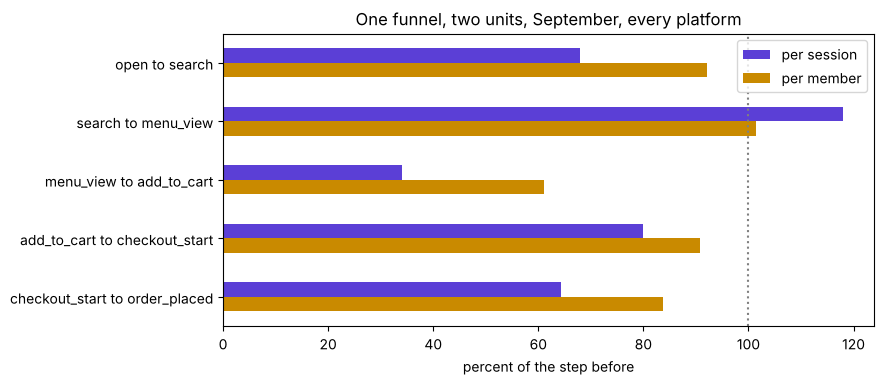

PASS  per session, menu view to add-to-cart prints 34 percent
PASS  per member, menu view to add-to-cart prints 61 percent


,per session,per member
open to search,68.0,92.1
search to menu_view,118.0,101.3
menu_view to add_to_cart,34.0,61.0
add_to_cart to checkout_start,80.0,90.8
checkout_start to order_placed,64.2,83.8


In [4]:
# The same September funnel counted in members, and both units drawn side by side.
per_member = sep.groupby("stage")["user_id"].nunique().reindex(stages)
both = pd.DataFrame({"per session": per_session.values[1:] / per_session.values[:-1],
                     "per member": per_member.values[1:] / per_member.values[:-1]},
                    index=[f"{a} to {b}" for a, b in zip(stages, stages[1:])])
ax = (100 * both).plot.barh(figsize=(8.4, 3.8), color=["#5B3FD6", "#C98A00"])
ax.invert_yaxis(); ax.axvline(100, ls=":", color="grey"); ax.set_xlabel("percent of the step before")
ax.set_title("One funnel, two units, September, every platform"); plt.show()
check("per session, menu view to add-to-cart prints 34 percent", round(100 * both.loc["menu_view to add_to_cart", "per session"]) == 34)
check("per member, menu view to add-to-cart prints 61 percent", round(100 * both.loc["menu_view to add_to_cart", "per member"]) == 61)
(100 * both).round(1)

**What happened.** The answer is c: 61 percent per member against 34 per session. Neither is
wrong; each answers a different question, and a chart that does not name its unit invites
the wrong one. Per member, search to menu view still reads 101 percent, because some members
only ever used the carousel: counting members shrinks the artefact and leaves it in place. The
skippable step, not the unit, makes the 118. Every step reads higher per member, because a
member who fails in one session can succeed in another the same month: checkout start to order
reads 84 per member and 64 per session. This chart pools every platform and all of September,
so neither panel shows the loss on the ticket; it appears only once the rate is split by
platform and date, next.

## Where did add-to-cart to order fall after 14 September, and for whom?

Add-to-cart to order is sessions that placed an order over sessions that added to a cart. Before
is 1 August to 13 September, after is 14 to 30 September. **Predict before you run.** Who does
the fall belong to?

- a) Everyone, on every platform
- b) Members on every platform
- c) Members on Android
- d) Non-members on Android

side                before  after
is_member platform               
False     android     52.0   51.0
          ios         55.0   55.0
          web         50.0   50.0
True      android     58.0   44.0
          ios         57.0   56.0
          web         55.0   55.0


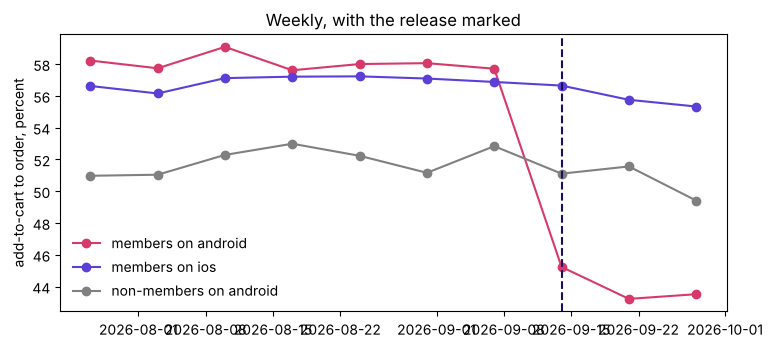

week
2026-07-27    58.2
2026-08-03    57.7
2026-08-10    59.1
2026-08-17    57.6
2026-08-24    58.0
2026-08-31    58.1
2026-09-07    57.7
2026-09-14    45.2
2026-09-21    43.2
2026-09-28    43.5
PASS  members on Android: 58 before, 44 after
PASS  members on iOS: 57 before, 56 after
PASS  non-members on Android: 52 before, 51 after


In [5]:
# Carts and orders by membership, platform and side of the release, then the rate.
# size() counts rows in each group; unstack() turns the last part of the row label into columns,
# once for the stages and once more for the side of the release.
flow = ev[ev["stage"].isin(["add_to_cart", "checkout_start", "order_placed"])].copy()
flow["side"] = (flow["event_ts"] >= "2026-09-14").map({False: "before", True: "after"})
counts = flow.groupby(["is_member", "platform", "side", "stage"]).size().unstack()
rate = (counts["order_placed"] / counts["add_to_cart"]).unstack()[["before", "after"]]
print((100 * rate).round(1))
# The weekly view, Monday to Sunday: the members' Android line breaks in the release week and no other line does.
flow["week"] = flow["event_ts"].dt.to_period("W-SUN").dt.start_time
fig, ax = plt.subplots(figsize=(8.6, 3.6))
for (m, p), colour in [((True, "android"), "#D63A6A"), ((True, "ios"), "#5B3FD6"), ((False, "android"), "grey")]:
    g = flow[(flow["is_member"] == m) & (flow["platform"] == p)].groupby(["week", "stage"]).size().unstack()
    ax.plot(g.index, 100 * g["order_placed"] / g["add_to_cart"], marker="o", color=colour,
            label=("members" if m else "non-members") + " on " + p)
ax.axvline(pd.Timestamp("2026-09-14"), ls="--", color="#1A0F5C"); ax.legend(frameon=False)
ax.set_ylabel("add-to-cart to order, percent"); ax.set_title("Weekly, with the release marked"); plt.show()
g = flow[flow["is_member"] & (flow["platform"] == "android")].groupby(["week", "stage"]).size().unstack()
print((100 * g["order_placed"] / g["add_to_cart"]).round(1).to_string())
check("members on Android: 58 before, 44 after", [round(100 * v) for v in rate.loc[(True, "android")]] == [58, 44])
check("members on iOS: 57 before, 56 after", [round(100 * v) for v in rate.loc[(True, "ios")]] == [57, 56])
check("non-members on Android: 52 before, 51 after", [round(100 * v) for v in rate.loc[(False, "android")]] == [52, 51])

**What happened.** The answer is c. Members on Android fell from 58 to 44 percent: about 58 in
each of the seven weeks before the release, then 45, 43 and 44. Members on iOS held at 57 to
56, and non-members on Android at 52 to 51. **The plausible wrong answer** is "the drop is at
add-to-cart to order for everyone, so the whole checkout flow is broken". The split by
membership, platform and date puts it in one place, so the app team is right that the stage
works everywhere else.

## Which step inside the checkout changed, and how many orders a week does it cost?

Add-to-cart to order has two steps inside it: starting checkout, and completing the order once
checkout has started. The two multiply: the share of carts that start checkout, times the share
of started checkouts that end in an order, is the share of carts that end in an order.

        cart to checkout start  checkout start to order
side                                                   
before                    80.0                     72.5
after                     80.0                     55.0
the two steps multiplied: {'before': 58.0, 'after': 44.0}
PASS  starting checkout held at 80 percent; completing it fell from 72.5 to 55
PASS  the two steps multiply back to 58 and 44


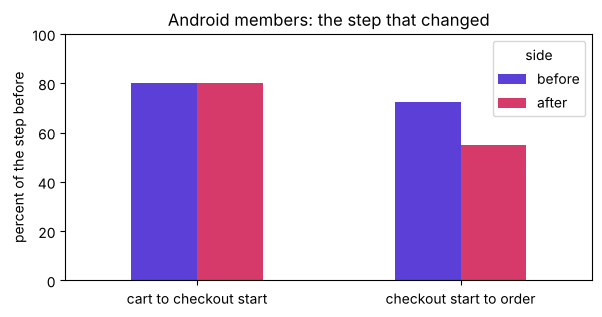

0.14 x 22,841 carts = 3,198 orders in 17 days, 188 a day, 1,317 a week
against iOS members (+7%): 1,266 orders a week lost
against non-members on Android (+4%): 1,133 orders a week lost
PASS  about 1,317 a week from the carts; 1,133 to 1,266 counted in orders placed


In [6]:
# Android members, the two steps inside the checkout, before and after the release.
andm = flow[flow["is_member"] & (flow["platform"] == "android")]
n = andm.groupby(["side", "stage"]).size().unstack().loc[["before", "after"]]
inside = pd.DataFrame({"cart to checkout start": n["checkout_start"] / n["add_to_cart"],
                       "checkout start to order": n["order_placed"] / n["checkout_start"]})
print((100 * inside).round(1))
print("the two steps multiplied:", (100 * inside.prod(axis=1)).round(0).to_dict())
check("starting checkout held at 80 percent; completing it fell from 72.5 to 55",
      [round(100 * v, 1) for v in inside["cart to checkout start"]] == [80.0, 80.0]
      and [round(100 * v, 1) for v in inside["checkout start to order"]] == [72.5, 55.0])
check("the two steps multiply back to 58 and 44", [round(100 * v) for v in inside.prod(axis=1)] == [58, 44])
ax = (100 * inside.T).plot.bar(figsize=(6.8, 3.2), color=["#5B3FD6", "#D63A6A"], rot=0)
ax.set_ylabel("percent of the step before"); ax.set_ylim(0, 100)
ax.set_title("Android members: the step that changed"); plt.show()
# The size, step by step: the fall times the carts, then per day and per week.
carts_after = n.loc["after", "add_to_cart"]
fall = rate.loc[(True, "android"), "before"] - rate.loc[(True, "android"), "after"]
lost_17 = fall * carts_after
print(f"{fall:.2f} x {carts_after:,} carts = {lost_17:,.0f} orders in 17 days, "
      f"{lost_17 / 17:,.0f} a day, {lost_17 / 17 * 7:,.0f} a week")
# The same loss counted in orders placed, which keeps any failed cart that came back as a later order:
# Android members' orders a week against the change iOS members and non-members on Android showed.
per_week = flow[flow["stage"] == "order_placed"].groupby(["is_member", "platform", "side"]).size().unstack()
per_week = per_week.assign(before=per_week["before"] / 44 * 7, after=per_week["after"] / 17 * 7)
change = per_week["after"] / per_week["before"] - 1
for who, name in [((True, "ios"), "iOS members"), ((False, "android"), "non-members on Android")]:
    expected = per_week.loc[(True, "android"), "before"] * (1 + change.loc[who])
    print(f"against {name} ({change.loc[who]:+.0%}): {expected - per_week.loc[(True, 'android'), 'after']:,.0f} "
          f"orders a week lost")
check("about 1,317 a week from the carts; 1,133 to 1,266 counted in orders placed",
      round(lost_17 / 17 * 7) == 1317 and round(per_week.loc[(True, "android"), "before"] * (1 + change.loc[(False, "android")])
                                                - per_week.loc[(True, "android"), "after"]) == 1133)

**What happened.** Starting checkout held at 80 percent; completing an order once checkout had
started fell from 72.5 to 55 percent. The two multiply back to the ticket's numbers: 0.80 x
72.5 = 58 before, and 0.80 x 55 = 44 after. **The size.** Android members added to a cart
22,841 times in the 17 days after the release. At 58 percent instead of 44, 0.14 x 22,841 is
about 3,198 more orders in 17 days, about 188 a day, about 1,317 a week, against about 5,064
Android member orders a week before the release: about a quarter of them.

**What happened.** About 1,317 orders a week if none of the failed carts came back as a later
order. Counted in orders placed, which keeps the ones that did, Android members' weekly orders
fell 18 percent while iOS members' rose 7 and non-members' on Android 4: a loss of 1,266 a week
against iOS members and 1,133 against non-members, so the range is 1,133 to 1,317. At an order
value of Rs 400, an assumption anywhere from Rs 300 to Rs 500, that is Rs 3.4 to 6.6 lakh of
orders a week, Rs 5.3 lakh at 1,317 and Rs 400. That is order value: Zomato keeps only its
commission and fees from it, so the loss to Zomato itself is a share of that range.

## What could still make the call wrong, and which check settles each?

Four doubts a careful reviewer raises before believing the step. (1) The comparators above were
read on add-to-cart to order, while the step blamed is checkout start to order: they belong on
the same step. (2) The August cohort aged from its month zero into its month one across the
cut, so "members on iOS held" mixes cohorts of different ages: hold the cohorts fixed by
reading only members who joined before August. (3) The release renamed an Android event, and
a date test cannot separate a logging fault from a broken checkout, since both start on 14
September: count the orders a second way, in member_months, which the app's event names do not
touch. (4) A small comparator can "hold" by chance: size each rate by how many sessions sit
under it.

In [7]:
# (1) and (2): checkout start to order, the same step for everyone, then with the cohorts held fixed.
members = pd.read_csv("../data/C2_W04_D04_members_STUDENT.csv")
cohort = members.set_index("member_id")["cohort_month"]
same_step = (counts["order_placed"] / counts["checkout_start"]).unstack()[["before", "after"]]
print("checkout start to order, everyone:"); print((100 * same_step).round(1))
held = flow[flow["is_member"] & (flow["user_id"].map(cohort) < "2026-08")]
hc = held.groupby(["platform", "side", "stage"]).size().unstack()
held_rate = (hc["order_placed"] / hc["checkout_start"]).unstack()[["before", "after"]]
print("\nmembers who joined before August:"); print((100 * held_rate).round(1))
check("on the same step, iOS members and non-members on Android move by under 1.5 points",
      abs(same_step.loc[(True, "ios")].diff().iloc[-1]) < 0.015
      and abs(same_step.loc[(False, "android")].diff().iloc[-1]) < 0.015)
check("held fixed, Android completion falls 70.3 to 53.6 while iOS holds at 68.6 to 69.3",
      [round(100 * v, 1) for v in held_rate.loc["android"]] == [70.3, 53.6]
      and [round(100 * v, 1) for v in held_rate.loc["ios"]] == [68.6, 69.3])

checkout start to order, everyone:
side                before  after
is_member platform               
False     android     65.0   63.7
          ios         68.7   68.8
          web         62.5   62.5
True      android     72.5   55.0
          ios         71.3   70.0
          web         68.7   68.8



members who joined before August:
side      before  after
platform               
android     70.3   53.6
ios         68.6   69.3
web         66.2   67.2
PASS  on the same step, iOS members and non-members on Android move by under 1.5 points
PASS  held fixed, Android completion falls 70.3 to 53.6 while iOS holds at 68.6 to 69.3


In [8]:
# (3): the orders counted a second way, the checkout version, and the cut moved a week either way.
mm = pd.read_csv("../data/C2_W04_D04_member_months_STUDENT.csv")
placed = ev[ev["is_member"] & (ev["stage"] == "order_placed")]
from_events = placed.groupby(placed["event_ts"].dt.strftime("%Y-%m")).size()
from_records = mm[mm["month"].isin(["2026-08", "2026-09"])].groupby("month")["orders"].sum()
print(pd.DataFrame({"member_months": from_records, "event log": from_events}))
check("the order records and the event log count the same orders in August and in September",
      from_records.to_dict() == from_events.to_dict())
sessions = ev.drop_duplicates("session_id")
android_after = sessions[(sessions["platform"] == "android") & (sessions["event_ts"] >= "2026-09-14")]
others = sessions.drop(android_after.index)
check("every Android session from 14 September runs checkout v2, and no other session does",
      (android_after["checkout_version"] == "v2").all() and (others["checkout_version"] == "v1").all())
am = flow[flow["is_member"] & (flow["platform"] == "android")]
for cut in ["2026-09-07", "2026-09-14", "2026-09-21"]:
    c = am.groupby([am["event_ts"] >= cut, "stage"]).size().unstack()
    r = c["order_placed"] / c["add_to_cart"]
    print(f"cut on {cut}: before {100 * r[False]:.0f}, after {100 * r[True]:.0f}")
# (4): how far chance can move each rate, and whether members who failed came back within a day.
starts_after = counts["checkout_start"].unstack()["after"]
for who in [(True, "android"), (False, "android")]:
    n_ = starts_after.loc[who]
    print(f"{'members' if who[0] else 'non-members'} on {who[1]}: {n_:,} checkout starts after the "
          f"release, so chance moves the rate by about {100 / n_ ** 0.5:.1f} points either way")
a = ev[ev["is_member"] & (ev["platform"] == "android")]
s = a.groupby("session_id").agg(user_id=("user_id", "first"), t=("event_ts", "min"))
s = s.join(a.pivot_table(index="session_id", columns="stage", values="user_id", aggfunc="size", fill_value=0).gt(0))
failed = s[s["checkout_start"] & ~s["order_placed"]].sort_values("t")
later = s[s["order_placed"]].sort_values("t")[["user_id", "t"]].rename(columns={"t": "next_order"})
nxt = pd.merge_asof(failed, later, left_on="t", right_on="next_order", by="user_id",
                    direction="forward", allow_exact_matches=False)
nxt["within_a_day"] = (nxt["next_order"] - nxt["t"]) <= pd.Timedelta(days=1)
after = nxt["t"] >= "2026-09-14"
retry = nxt.groupby(after)["within_a_day"].agg(["mean", "size", "sum"])
retry = retry.assign(failed_a_week=retry["size"] / [44, 17] * 7, came_back_a_week=retry["sum"] / [44, 17] * 7)
print(retry.round(3))
check("the share of failures followed by an order within a day did not rise",
      retry.loc[True, "mean"] <= retry.loc[False, "mean"])

         member_months  event log
2026-08          33699      33699
2026-09          27212      27212
PASS  the order records and the event log count the same orders in August and in September


PASS  every Android session from 14 September runs checkout v2, and no other session does
cut on 2026-09-07: before 58, after 47


cut on 2026-09-14: before 58, after 44
cut on 2026-09-21: before 56, after 43
members on android: 18,273 checkout starts after the release, so chance moves the rate by about 0.7 points either way
non-members on android: 1,600 checkout starts after the release, so chance moves the rate by about 2.5 points either way


        mean   size   sum  failed_a_week  came_back_a_week
t                                                         
False  0.365  12074  4404       1920.864           700.636
True   0.351   8223  2887       3385.941          1188.765
PASS  the share of failures followed by an order within a day did not rise


In [9]:
# Fewer users or less use, with the cohorts held fixed: orders per ordering member, by platform.
platform = ev[ev["is_member"]].groupby("user_id")["platform"].first()      # one platform per member here
act = mm[mm["month"].isin(["2026-08", "2026-09"]) & (mm["orders"] > 0)].copy()
act["platform"] = act["member_id"].map(platform)
act["cohort"] = act["member_id"].map(cohort)
mixed = act.pivot_table(index="platform", columns="month", values="orders", aggfunc="mean")
fixed = act[act["cohort"] < "2026-08"].pivot_table(index="platform", columns="month", values="orders", aggfunc="mean")
print("every ordering member:"); print(mixed.round(2))
print("\nordering members who joined before August:"); print(fixed.round(2))
check("held fixed, Android members order less each (1.45 to 1.24) while iOS holds",
      [round(v, 2) for v in fixed.loc["android"]] == [1.45, 1.24] and abs(fixed.loc["ios"].diff().iloc[-1]) < 0.02)

every ordering member:
month     2026-08  2026-09
platform                  
android      1.36     1.20
ios          1.34     1.40
web          1.37     1.42

ordering members who joined before August:
month     2026-08  2026-09
platform                  
android      1.45     1.24
ios          1.44     1.45
web          1.48     1.46
PASS  held fixed, Android members order less each (1.45 to 1.24) while iOS holds


**What happened.** (1) On the step blamed, iOS members went from 71 to 70 percent and
non-members on Android from 65 to 64, while Android members fell from 72.5 to 55. (2) Held
fixed to members who joined before August, Android completion fell from 70.3 to 53.6 and iOS
held at 68.6 to 69.3: the fall does not come from the August cohort's ageing. (3) The order
records and the event log count the same orders, 33,699 in August and 27,212 in September, so
no orders went missing from the count after the rename: the fall is in orders placed. Every
Android session from 14 September ran the new checkout, so the date and the version are one
split here, and only a staged release would let them be read apart. Moving the cut a week
either way keeps the fall, 58 to 47 and 56 to 43, and the weekly series dates it to the release
week. (4) The 55 rests on 18,273 checkout starts, so chance moves it by under a point; the
non-members' comparator rests on 1,600, so "held" there means within about 2.5 points. After
a checkout with no order, the member ordered within a day 36.5 percent of the time before the
release and 35.1 after; failures nearly doubled, from 1,921 to 3,386 a week, so more came back,
1,189 a week against 701, which is why the size's floor is counted in orders placed. Held
fixed, Android members also ordered less each, 1.45 to 1.24 orders per
ordering member from August to September, while iOS held at 1.44 and 1.45. Over every ordering
member the same ratio reads 1.36 to 1.20 on Android and 1.34 to 1.40 on iOS, and that iOS "rise"
is the mix of cohorts again.

**The questions, answered.** (1) Per session, the steps read 68, 118, 34, 80 and 64 percent.
(2) Search to menu view reads 118 because the carousel skips search; among sessions that
searched it reads 89. (3) Per session asks how often a menu visit becomes a cart (34 percent);
per member asks how many browsing members ever added to a cart (61 percent). (4) The fall
belongs to members on Android, 58 to 44 percent, from the release week. (5) The step that
changed is checkout start to order placed, 72.5 to 55 percent, about 1,133 to 1,317 orders a
week. (6) The same-step comparators, the cohorts held fixed, the order records and the size of
each sample all leave the call standing.